# Dataset Type

In [ ]:
DATASET_TYPE = "downloaded" # Options are "internal" or "downloaded"

# Load Scikit-Learn Internal Data

In [ ]:
# Import scikit-learn dataset library
from sklearn import datasets

if DATASET_TYPE == "internal":
  lr_data = datasets.load_iris()

  X = lr_data.data
  y = lr_data.target
  feature_names = lr_data.feature_names
  labels = lr_data.target_names
  cm_labels = labels

# OR: Download Real Dataset

In [ ]:
import numpy as np
import pandas as pd

if DATASET_TYPE == "downloaded":
  lr_data = pd.read_csv('http://nrvis.com/data/mldata/breast-cancer-wisconsin_wdbc.csv')

  X = lr_data.iloc[:, 2:]
  y = lr_data.iloc[:, 1]
  feature_names = lr_data.columns
  labels = feature_names[1]
  cm_labels = ["malignant", "benign"]

  # Map labels from ['M', 'B'] to [0, 1] space
  y = np.where(y=='M', 0, 1)

# Explore the Data

In [ ]:
# print the names of the features
print("Features: ", feature_names)

# print the label type of targets
print("Labels: ", labels)

Features:  ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Labels:  ['setosa' 'versicolor' 'virginica']


# Scale the data

In [ ]:
# Image processing and pixel values - min-max scaling
# knn-clustering or regression which use distance metrics - standardization
# SVM or logistic regression or Neural Network which use gradiant descent - standardization
# decision tree and random forest - not distance based, hence no scaling is needed

# Normalize the data - Convert to range [0, 1]
# X = (X - np.min(X)) / (np.max(X) - np.min(X))
# Standardize the data - Convert to a normal distribution with mean 0 and standard deviation of 1
X = (X - np.mean(X)) / np.std(X)

# Split the Data into Train and Test Sets

In [ ]:
# Import train_test_split function
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((120, 4), (30, 4), (120,), (30,))

# Train the Model

In [ ]:
from sklearn.linear_model import LogisticRegression

# Update hyperparameters for the LogisticRegression function using paraemters defined in -
# https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

# Create Logistic Regression object
clf = LogisticRegression()

# Train Logistic Regression Classifer
clf.fit(X_train, y_train)

LogisticRegression(C=1.0, class_weight=None, dual=False, fit_intercept=True,
                   intercept_scaling=1, l1_ratio=None, max_iter=100,
                   multi_class='auto', n_jobs=None, penalty='l2',
                   random_state=None, solver='lbfgs', tol=0.0001, verbose=0,
                   warm_start=False)

# Predict the Model on Test Data

In [ ]:
#Predict the response for test dataset
y_pred = clf.predict(X_test)

# Evaluate on Test data

In [ ]:
#Import scikit-learn metrics module for accuracy calculation
from sklearn import metrics

# Model Accuracy: how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

# Model Precision: what percentage of positive tuples are labeled as such?
#print("Precision:",metrics.precision_score(y_test, y_pred))

# Model Recall: what percentage of positive tuples are labelled as such?
#print("Recall:",metrics.recall_score(y_test, y_pred))

Accuracy: 1.0


# Plot Confusion Matrix

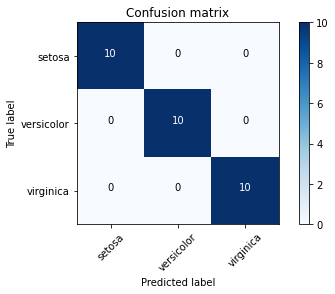

In [ ]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

def plot_confusion_matrix(cm, classes, normalize=False, title='Confusion matrix', cmap=plt.cm.Blues):
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt), horizontalalignment="center", color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

cm = confusion_matrix(y_test, y_pred)

plot_confusion_matrix(cm, cm_labels)  
plt.show()